# Segmentation des anomalies avec SegFormer (DSO 1)

**Syrine.** Suite de **data\_preparation.ipynb**. Le modèle dit **où** est le danger : pour chaque pixel, est-ce une anomalie (1) ou le fond (0) ?

SegFormer est différent des modèles de Hasna (U-Net) et Riadh (DeepLabV3+) : son encodeur n'est pas un CNN classique mais un
**Transformer** (Mix Transformer, « MiT »), qui utilise l'**attention** pour relier des zones éloignées de l'image.

On reprend les mêmes réglages que le U-Net v2 de Hasna et le DeepLabV3+ de Riadh, pour que la comparaison du DSO 1 soit **équitable** :

1. **Variations aléatoires** sur le train (zoom / recadrage, retournement, couleurs), appliquées à l'image **et** au masque ensemble
2. **Moins de poids entraînés** : seul le dernier étage de l'encodeur (stage 4) est dégelé
3. **Dropout** avant la tête 1 × 1

Objectif du DSO 1 : **IoU ≥ 0,5 et AP ≥ 0,6**.

## 0. Installation (une seule fois)

In [1]:
%pip install -U segmentation-models-pytorch timm

Note: you may need to restart the kernel to use updated packages.


**Explication :** installe ou met à jour `segmentation_models_pytorch` (smp), qui contient SegFormer (version 0.4 ou plus récente), et `timm`, utilisé par l'encodeur Transformer. À exécuter une seule fois, puis **redémarrer le kernel** (Kernel → Restart).

## 1. Import

In [2]:
import os, time                                   # chemins et mesure du temps
import numpy as np                                # calculs sur les tableaux
import pandas as pd                               # tableaux (etiquettes.csv)
import matplotlib.pyplot as plt                   # graphiques et images
from PIL import Image, ImageEnhance               # ouvrir images et masques ; changer luminosité / contraste / couleurs
import torch                                      # PyTorch
import torch.nn as nn                             # couches (Conv2d, Dropout2d)
import torch.nn.functional as F                   # fonctions de perte (BCE)
from torch.utils.data import Dataset, DataLoader  # lecture des données par paquets
import segmentation_models_pytorch as smp         # SegFormer pré-entraîné
from sklearn.metrics import roc_auc_score, average_precision_score   # AUROC et AP au niveau pixel

DOSSIER_MANUEL = r""                              # si besoin, colle ici le chemin du dossier contenant DataPreparation (sinon recherche automatique)

def trouver_prep():                                # cherche DataPreparation/etiquettes.csv sans dépendre d'un chemin fixe
    home = os.path.expanduser("~")
    racines = [DOSSIER_MANUEL, os.getcwd(), os.path.join(home, "Desktop"), os.path.join(home, "Documents"), os.path.join(home, "Downloads")]
    for racine in racines:
        if not racine or not os.path.isdir(racine):
            continue
        for chemin, dossiers, fichiers in os.walk(racine):
            if chemin.count(os.sep) - racine.count(os.sep) >= 5:   # profondeur max 5
                dossiers[:] = []
            if os.path.basename(chemin) == "DataPreparation" and "etiquettes.csv" in fichiers:
                return chemin
    raise FileNotFoundError("DataPreparation/etiquettes.csv introuvable : renseigne DOSSIER_MANUEL ci-dessus.")

PREP = trouver_prep()                              # images et masques préparés
print("Données :", PREP)

torch.manual_seed(42); np.random.seed(42)                   # résultats reproductibles
device = "cuda" if torch.cuda.is_available() else "cpu"     # GPU s'il existe, sinon CPU
print("Appareil :", device)

Données : C:\Users\MSI\Desktop\RoadAnomaly\frames\DataPreparation
Appareil : cuda


**Explication :** on importe les bibliothèques et on **retrouve automatiquement** `DataPreparation` (images 512 × 512 et masques 0 / 1) : si la recherche échoue, renseigne `DOSSIER_MANUEL`. `manual_seed` rend les résultats reproductibles.

## 2. Chargement des données

In [3]:
TAILLE = 256                                      # 256 x 256 : 4 fois plus rapide que 512 sur CPU (mettre 512 sur GPU)
MOYENNE = np.array([0.485, 0.456, 0.406])         # moyenne ImageNet (R, G, B)
ECART = np.array([0.229, 0.224, 0.225])           # écart-type ImageNet
etiquettes = pd.read_csv(f"{PREP}/etiquettes.csv")   # nom et ensemble de chaque image

class SegDataset(Dataset):                        # donne une image et son masque
    def __init__(self, ensemble):
        self.ensemble = ensemble
        self.df = etiquettes[etiquettes.ensemble == ensemble].reset_index(drop=True)   # images de cet ensemble
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        nom = self.df.nom[i]
        img = Image.open(f"{PREP}/{self.ensemble}/images/{nom}.png").convert("RGB")
        masque = Image.open(f"{PREP}/{self.ensemble}/masques/{nom}.png")
        if self.ensemble == "train":                                 # variations aléatoires, train seulement
            cote = int(min(img.size) * np.random.uniform(0.7, 1.0))  # zoom : on garde 70 à 100 % de l'image (carré)
            x0 = np.random.randint(0, img.width - cote + 1)          # position au hasard
            y0 = np.random.randint(0, img.height - cote + 1)
            boite = (x0, y0, x0 + cote, y0 + cote)
            img, masque = img.crop(boite), masque.crop(boite)        # même recadrage pour l'image ET le masque
            for f in (ImageEnhance.Brightness, ImageEnhance.Contrast, ImageEnhance.Color):
                img = f(img).enhance(np.random.uniform(0.7, 1.3))    # luminosité, contraste, couleurs (image seulement)
        img = img.resize((TAILLE, TAILLE), Image.BILINEAR)
        masque = masque.resize((TAILLE, TAILLE), Image.NEAREST)      # NEAREST : garde 0 / 1
        img = (np.array(img) / 255.0 - MOYENNE) / ECART              # pixels 0..1 puis normalisation ImageNet
        masque = np.array(masque, dtype=np.float32)                  # 0 = fond, 1 = anomalie
        if self.ensemble == "train" and np.random.rand() < 0.5:      # train : 1 fois sur 2...
            img, masque = img[:, ::-1], masque[:, ::-1]              # ...retourne image ET masque ensemble
        img = torch.tensor(img.transpose(2, 0, 1).copy(), dtype=torch.float32)   # format PyTorch : canaux, hauteur, largeur
        masque = torch.tensor(masque.copy()).unsqueeze(0)            # 1 canal
        return img, masque

train_ds, val_ds, test_ds = SegDataset("train"), SegDataset("val"), SegDataset("test")
train_dl = DataLoader(train_ds, batch_size=8, shuffle=True, drop_last=True)   # paquets de 8 images ; drop_last : jamais de paquet d'1 image (BatchNorm du décodeur)
val_dl = DataLoader(val_ds, batch_size=8)
test_dl = DataLoader(test_ds, batch_size=8)
print(len(train_ds), "images train,", len(val_ds), "val,", len(test_ds), "test")

698 images train, 139 val, 163 test


**Explication :** le `Dataset` lit chaque image et son masque, les met en **256 × 256** (image avec `BILINEAR`, masque avec `NEAREST` pour garder seulement 0 et 1) et normalise l'image comme ImageNet. Pour le **train seulement**, chaque image change à chaque époque : on garde une zone au hasard de 70 à 100 % de l'image (zoom), on change luminosité, contraste et couleurs, et on la retourne une fois sur deux. Le recadrage et le retournement sont appliqués **au masque aussi**, pour qu'il reste aligné ; les couleurs ne touchent que l'image. Le modèle ne voit donc jamais deux fois la même image, ce qui l'empêche d'apprendre par cœur. Batch = **8**, comme Hasna : SegFormer-B0 est léger. `drop_last=True` évite un dernier paquet d'une seule image, qui ferait planter la BatchNorm du décodeur. Sur GPU (Colab), on peut mettre `TAILLE = 512`.

## 3. Visualisation

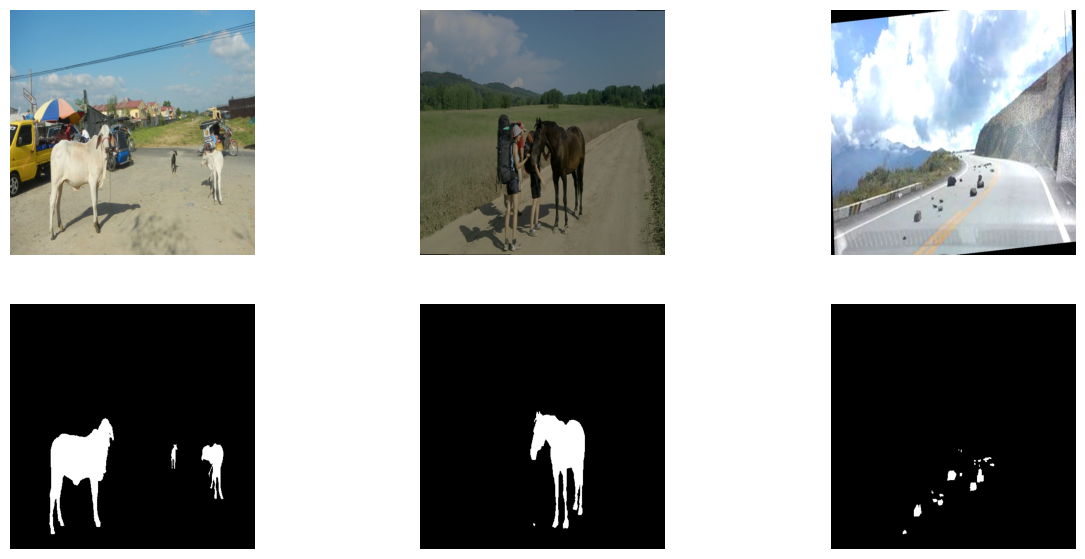

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j in range(3):
    nom = train_ds.df.nom[j * 200]                                      # 3 images différentes du train
    ax[0, j].imshow(Image.open(f"{PREP}/train/images/{nom}.png"))     # image
    ax[1, j].imshow(Image.open(f"{PREP}/train/masques/{nom}.png"), cmap="gray")   # masque : blanc = anomalie
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.show()

**Explication :** en haut les images, en bas leurs masques (blanc = anomalie). C'est exactement ce que le modèle doit apprendre à dessiner.

## 4. Création du modèle

In [5]:
model = smp.Segformer("mit_b0", encoder_weights="imagenet", classes=1)   # SegFormer, encodeur Mix Transformer B0 pré-entraîné ImageNet, 1 canal
model.segmentation_head = nn.Sequential(nn.Dropout2d(0.2), *model.segmentation_head)   # Dropout ajouté avant la tête d'origine (conv 1 x 1 + agrandissement x4)
model = model.to(device)                                              # sur GPU ou CPU
print(model)                                                          # toute l'architecture

config.json:   0%|          | 0.00/135 [00:00<?, ?B/s]

C:\Users\MSI\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\MSI\.cache\huggingface\hub\models--smp-hub--mit_b0.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\MSI\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system u

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Segformer(
  (encoder): MixVisionTransformerEncoder(
    (patch_embed1): OverlapPatchEmbed(
      (proj): Conv2d(3, 32, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
      (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (patch_embed2): OverlapPatchEmbed(
      (proj): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (patch_embed3): OverlapPatchEmbed(
      (proj): Conv2d(64, 160, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (norm): LayerNorm((160,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (patch_embed4): OverlapPatchEmbed(
      (proj): Conv2d(160, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    )
    (block1): Sequential(
      (0): Block(
        (norm1): LayerNorm((32,), eps=1e-06, elementwise_affine=True, bias=True)
      

**Explication :** SegFormer a deux parties. L'**encodeur** (Mix Transformer B0, pré-entraîné ImageNet) découpe l'image en petits morceaux qui se chevauchent (*patches*), puis l'**attention** permet à chaque morceau de « regarder » tous les autres : le modèle voit le **contexte global** (un objet posé sur la route, pas sur le bas-côté). Il travaille sur **4 étages** de plus en plus petits (1/4, 1/8, 1/16, 1/32 de l'image), donc il voit les petits et les gros objets. Le **décodeur** est très simple : des couches **fully connected (MLP)** ramènent les 4 étages à la même taille et les fusionnent. Version **B0** = la plus légère (environ 3,7 millions de paramètres), adaptée au CPU ; sur GPU on peut essayer `mit_b2`. `classes=1` : une seule sortie, la probabilité d'anomalie de chaque pixel. La tête d'origine est déjà une **conv 1 × 1** ; on ajoute seulement un **Dropout** avant elle, pour limiter l'apprentissage par cœur.

## 5. Architecture

In [6]:
couches = pd.Series([type(m).__name__ for m in model.modules()]).value_counts()   # compte chaque type de couche
print(couches.reindex(["Conv2d", "GELU", "ReLU", "Linear", "Softmax"]).fillna(0).astype(int))   # convolution, activations, fully connected
print("Réduction par étage :", [model.encoder.patch_embed1.proj.stride, model.encoder.patch_embed2.proj.stride,
                                 model.encoder.patch_embed3.proj.stride, model.encoder.patch_embed4.proj.stride])   # convolutions à pas (stride) qui réduisent l'image
print("Décodeur MLP :", getattr(model.decoder, "mlp_stage", model.decoder))                                  # couches fully connected du décodeur
print("Tête :", model.segmentation_head)                                         # Dropout + conv 1 x 1 + agrandissement
print("Paramètres :", round(sum(p.numel() for p in model.parameters()) / 1e6, 1), "millions")

Conv2d     20
GELU        8
ReLU        1
Linear     44
Softmax     0
Name: count, dtype: int64
Réduction par étage : [(4, 4), (2, 2), (2, 2), (2, 2)]
Décodeur MLP : ModuleList(
  (0): MLP(
    (linear): Linear(in_features=256, out_features=256, bias=True)
  )
  (1): MLP(
    (linear): Linear(in_features=160, out_features=256, bias=True)
  )
  (2): MLP(
    (linear): Linear(in_features=64, out_features=256, bias=True)
  )
  (3): MLP(
    (linear): Linear(in_features=32, out_features=256, bias=True)
  )
)
Tête : Sequential(
  (0): Dropout2d(p=0.2, inplace=False)
  (1): Conv2d(256, 1, kernel_size=(1, 1), stride=(1, 1))
  (2): Upsample(scale_factor=4.0, mode='bilinear')
  (3): Activation(
    (activation): Identity()
  )
)
Paramètres : 3.7 millions


**Explication :** on retrouve l'architecture imposée dans SegFormer, avec deux différences à expliquer au prof :

| Étape imposée | Dans SegFormer |
| --- | --- |
| 1. Convolution | `Conv2d` des *patch embeddings* (7 × 7 puis 3 × 3) qui découpent l'image en morceaux, et conv 3 × 3 dans chaque bloc (Mix-FFN) |
| 2. Activation | **`GELU`** dans l'encodeur (une version douce de ReLU, standard dans les Transformers) et **`ReLU`** dans le décodeur (fusion Conv → BatchNorm → ReLU) |
| 3. Pooling | Pas de couche `MaxPool` : la réduction de taille est faite par des **convolutions à pas 2 ou 4** (stride), qui jouent le même rôle que le pooling |
| 4. Fully Connected | Les `Linear` de l'attention et du **décodeur MLP** (vraies couches fully connected, appliquées à chaque position), puis la tête Dropout + conv **1 × 1** |
| 5. Output | 1 canal, agrandi × 4, + **Sigmoid** → probabilité d'anomalie de chaque pixel |

En plus : l'**attention** (`Softmax` dans chaque bloc) relie chaque morceau de l'image à tous les autres. C'est ce qui distingue un Transformer d'un CNN.

## 6. Perte et optimiseur

In [7]:
def dice_focal(logits, masque, alpha=0.75, gamma=2):        # perte de DataAugmentation.ipynb
    prob = torch.sigmoid(logits)                             # probabilité d'anomalie par pixel
    dice = 1 - (2 * (prob * masque).sum() + 1) / (prob.sum() + masque.sum() + 1)   # 1 - recouvrement prédiction / vrai masque
    bce = F.binary_cross_entropy_with_logits(logits, masque, reduction="none")    # erreur pixel par pixel
    pt = torch.exp(-bce)                                     # proche de 1 = pixel facile
    a = alpha * masque + (1 - alpha) * (1 - masque)          # plus de poids aux pixels anomalie
    focal = (a * (1 - pt) ** gamma * bce).mean()             # réduit le poids des pixels faciles (la route)
    return dice + focal

def passage(model, dl, optimiseur=None):                     # un passage sur un ensemble ; avec optimiseur = entraînement
    entrainement = optimiseur is not None
    model.train(entrainement)                                # mode entraînement ou évaluation
    perte_tot, inter, union, somme = 0, 0, 0, 0
    with torch.set_grad_enabled(entrainement):               # gradients seulement pendant l'entraînement
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            logits = model(x)                                # prédiction (avant Sigmoid)
            perte = dice_focal(logits, y)
            if entrainement:
                optimiseur.zero_grad(); perte.backward(); optimiseur.step()   # corrige les poids
            pred = (torch.sigmoid(logits) > 0.5).float()     # pixel = anomalie si probabilité > 0,5
            inter += (pred * y).sum().item()                 # pixels anomalie bien trouvés
            union += ((pred + y) > 0).sum().item()           # pixels anomalie prédits OU vrais
            somme += pred.sum().item() + y.sum().item()
            perte_tot += perte.item() * len(y)
    return perte_tot / len(dl.dataset), inter / max(union, 1), 2 * inter / max(somme, 1)   # perte, IoU, Dice

**Explication :** la perte **Dice + Focal** (expliquée dans DataAugmentation.ipynb) règle le déséquilibre : il y a environ 90 % de pixels de fond. La Dice mesure le recouvrement avec le vrai masque, la Focal se concentre sur les pixels difficiles. `passage` parcourt un ensemble : avec un optimiseur il entraîne, sans optimiseur il mesure seulement. Il renvoie la perte, l'**IoU** (pixels communs / pixels réunis) et le **Dice**.

## 7. Entraînement 1 : encodeur gelé

In [8]:
for p in model.encoder.parameters():
    p.requires_grad = False                    # encodeur gelé : ses poids ImageNet ne bougent pas
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-3, weight_decay=0.01)   # décodeur + tête

historique = []
for epoque in range(5):
    debut = time.time()
    perte_train, iou_train, _ = passage(model, train_dl, optimiseur)   # apprend
    perte_val, iou_val, _ = passage(model, val_dl)                     # mesure
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "iou_train": iou_train, "iou_val": iou_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   IoU {iou_train:.2f} / {iou_val:.2f}   ({time.time() - debut:.0f} s)")

Époque 1 : perte 0.425 / 0.721   IoU 0.48 / 0.27   (26 s)
Époque 2 : perte 0.240 / 0.564   IoU 0.74 / 0.34   (24 s)
Époque 3 : perte 0.205 / 0.660   IoU 0.77 / 0.31   (25 s)
Époque 4 : perte 0.192 / 0.559   IoU 0.78 / 0.39   (25 s)
Époque 5 : perte 0.182 / 0.547   IoU 0.79 / 0.39   (25 s)


**Explication :** l'encodeur est gelé : seuls le décodeur MLP et la tête apprennent, pendant 5 époques (lr = 0,001). Chaque ligne affiche train / validation et la durée de l'époque. Sur CPU, compte plusieurs minutes par époque.

## 8. Entraînement 2 : dernier bloc de l'encodeur + early stopping

In [9]:
for partie in [model.encoder.patch_embed4, model.encoder.block4, model.encoder.norm4]:   # stage 4 = dernier étage de l'encodeur
    for p in partie.parameters():
        p.requires_grad = True                 # on dégèle seulement le stage 4
optimiseur = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=0.01)   # lr 10 fois plus petit
print("Paramètres entraînés :", round(sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6, 1), "millions")

meilleur_iou, attente, PATIENCE = 0, 0, 8
for epoque in range(30):                       # 30 époques maximum
    debut = time.time()
    perte_train, iou_train, _ = passage(model, train_dl, optimiseur)
    perte_val, iou_val, _ = passage(model, val_dl)
    historique.append({"perte_train": perte_train, "perte_val": perte_val, "iou_train": iou_train, "iou_val": iou_val})
    print(f"Époque {epoque + 1} : perte {perte_train:.3f} / {perte_val:.3f}   IoU {iou_train:.2f} / {iou_val:.2f}   ({time.time() - debut:.0f} s)")
    if iou_val > meilleur_iou:                 # meilleure IoU de validation ?
        meilleur_iou, attente = iou_val, 0
        torch.save(model.state_dict(), "segformer_meilleur.pt")   # sauvegarde le meilleur modèle
    else:
        attente += 1
        if attente == PATIENCE:                # 8 époques sans progrès : early stopping
            print("Early stopping : l'IoU de validation ne progresse plus")
            break
print("Meilleure IoU de validation :", round(meilleur_iou, 3))

Paramètres entraînés : 2.4 millions
Époque 1 : perte 0.155 / 0.463   IoU 0.82 / 0.41   (24 s)
Époque 2 : perte 0.145 / 0.443   IoU 0.83 / 0.44   (25 s)
Époque 3 : perte 0.132 / 0.525   IoU 0.84 / 0.34   (25 s)
Époque 4 : perte 0.127 / 0.442   IoU 0.84 / 0.44   (25 s)
Époque 5 : perte 0.127 / 0.445   IoU 0.85 / 0.40   (25 s)
Époque 6 : perte 0.116 / 0.491   IoU 0.86 / 0.37   (25 s)
Époque 7 : perte 0.115 / 0.496   IoU 0.86 / 0.36   (25 s)
Époque 8 : perte 0.111 / 0.522   IoU 0.86 / 0.34   (25 s)
Époque 9 : perte 0.115 / 0.439   IoU 0.87 / 0.41   (25 s)
Époque 10 : perte 0.113 / 0.465   IoU 0.86 / 0.37   (25 s)
Époque 11 : perte 0.114 / 0.457   IoU 0.87 / 0.39   (26 s)
Époque 12 : perte 0.106 / 0.516   IoU 0.87 / 0.35   (26 s)
Early stopping : l'IoU de validation ne progresse plus
Meilleure IoU de validation : 0.441


**Explication :** comme pour Hasna et Riadh, on ne dégèle pas tout l'encodeur (trop de poids libres pour apprendre par cœur), seulement le **stage 4**, le dernier étage de l'encodeur (formes complexes), avec un lr 10 fois plus petit (0,0001). Les premiers étages (bords, textures) gardent leurs poids ImageNet. On sauvegarde le modèle chaque fois que l'**IoU de validation** s'améliore, et on arrête après **8** époques sans progrès (**early stopping**). Hasna avait 5, mais son entraînement s'est arrêté alors que la validation progressait encore.

## 9. Courbes

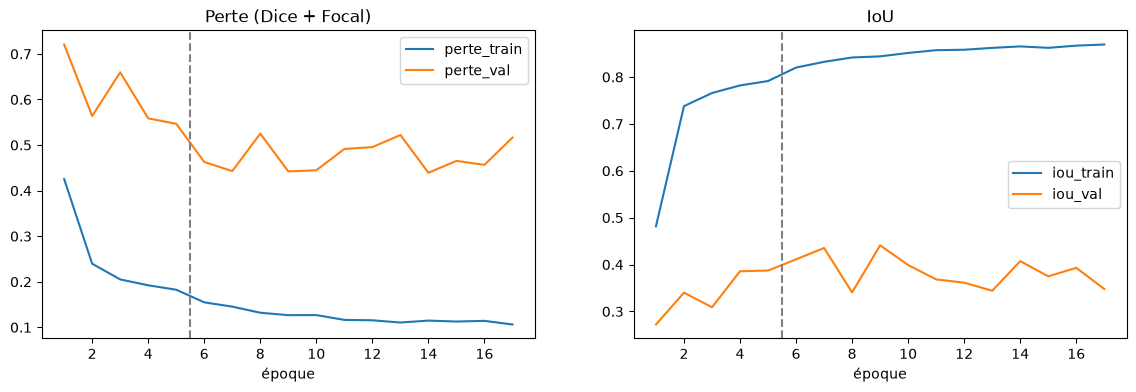

In [10]:
h = pd.DataFrame(historique); h.index = h.index + 1
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
h[["perte_train", "perte_val"]].plot(ax=ax[0], title="Perte (Dice + Focal)")
h[["iou_train", "iou_val"]].plot(ax=ax[1], title="IoU")
for a in ax:
    a.axvline(5.5, color="gray", linestyle="--")    # fin de l'entraînement 1
    a.set_xlabel("époque")
plt.show()

**Explication :** perte et IoU en train et en validation. Pas d'overfitting si la perte de validation descend avec celle du train et si l'écart d'IoU entre train et validation reste petit.

## 10. Validation / test

In [11]:
model.load_state_dict(torch.load("segformer_meilleur.pt", map_location=device))   # recharge le meilleur modèle

@torch.no_grad()
def probabilites(model, dl):                                  # probabilités et vrais pixels (1 pixel sur 16)
    model.eval(); P, Y = [], []
    for x, y in dl:
        P.append(torch.sigmoid(model(x.to(device))).cpu().numpy().ravel()[::16])
        Y.append(y.numpy().ravel()[::16])
    return np.concatenate(P), np.concatenate(Y)

for nom, dl in [("Validation", val_dl), ("Test", test_dl)]:
    _, iou, dice = passage(model, dl)                         # IoU et Dice (seuil 0,5)
    p, y = probabilites(model, dl)
    print(f"{nom} : IoU = {iou:.2f}   Dice = {dice:.2f}   AUROC = {roc_auc_score(y, p):.3f}   AP = {average_precision_score(y, p):.3f}")

Validation : IoU = 0.44   Dice = 0.61   AUROC = 0.973   AP = 0.728
Test : IoU = 0.75   Dice = 0.86   AUROC = 0.994   AP = 0.944


**Explication :** on recharge le meilleur modèle et on le mesure sur la validation puis, une seule fois, sur le test. **IoU** et **Dice** mesurent le recouvrement avec le vrai masque (seuil 0,5). **AUROC** et **AP** mesurent la qualité des probabilités sans choisir de seuil ; ce sont les métriques standard du dataset RoadAnomaly. On prend 1 pixel sur 16 pour aller plus vite, le résultat est presque identique. Objectif du DSO 1 : **IoU ≥ 0,5 et AP ≥ 0,6**.

## 11. Exemples : meilleures et pires prédictions

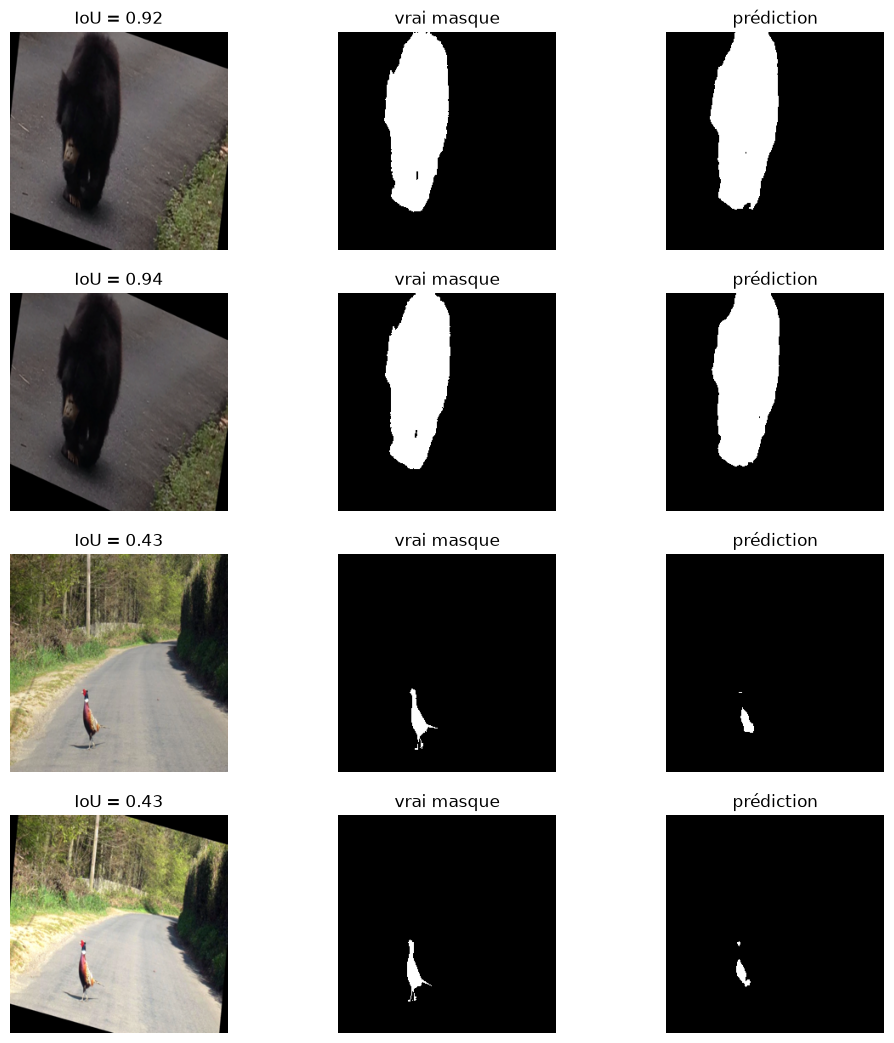

In [12]:
model.eval(); scores = []
with torch.no_grad():
    for i in range(len(test_ds)):
        x, y = test_ds[i]
        pred = (torch.sigmoid(model(x.unsqueeze(0).to(device))) > 0.5).float().cpu()[0]
        scores.append(((pred * y).sum() / (((pred + y) > 0).sum() + 1e-6)).item())   # IoU de cette image
ordre = np.argsort(scores)                                    # du pire au meilleur
fig, ax = plt.subplots(4, 3, figsize=(12, 13))
for ligne, i in enumerate(list(ordre[-2:]) + list(ordre[:2])):   # 2 meilleures puis 2 pires
    x, y = test_ds[i]
    pred = (torch.sigmoid(model(x.unsqueeze(0).to(device))) > 0.5).float().cpu()[0, 0]
    ax[ligne, 0].imshow(Image.open(f"{PREP}/test/images/{test_ds.df.nom[i]}.png").resize((TAILLE, TAILLE)))
    ax[ligne, 1].imshow(y[0], cmap="gray"); ax[ligne, 2].imshow(pred, cmap="gray")
    ax[ligne, 0].set_title(f"IoU = {scores[i]:.2f}"); ax[ligne, 1].set_title("vrai masque"); ax[ligne, 2].set_title("prédiction")
    for a in ax[ligne]: a.axis("off")
plt.show()

**Explication :** on calcule l'IoU de chaque image du test, puis on affiche les 2 meilleures et les 2 pires : image, vrai masque, masque prédit. Cela montre où le modèle réussit (gros objets bien contrastés) et où il se trompe (petits objets comme les cônes, objets qui ressemblent à la route).

## 12. Comparaison avec U-Net (Hasna) et DeepLabV3+ (Riadh)

In [13]:
_, iou_val, _ = passage(model, val_dl)                   # IoU de la version 2
_, iou_test, _ = passage(model, test_dl)
pd.DataFrame({
    "U-Net v2 (Hasna)": [0.93, 0.59, 0.78],              # scores copiés de seg_unet_v2.ipynb
    "DeepLabV3+ (Riadh)": [None, None, None],              # à remplir avec les scores de seg_deeplabv3.ipynb
    "SegFormer-B0": [round(historique[-1]["iou_train"], 2), round(iou_val, 2), round(iou_test, 2)],
}, index=["IoU train (dernière époque)", "IoU validation", "IoU test"])

,U-Net v2 (Hasna),DeepLabV3+ (Riadh),SegFormer-B0
IoU train (dernière époque),0.93,None,0.87
IoU validation,0.59,None,0.44
IoU test,0.78,None,0.75


**Explication :** on compare SegFormer avec le U-Net v2 de Hasna et le DeepLabV3+ de Riadh (colonne à remplir avec ses scores), entraînés sur les mêmes données avec les mêmes réglages. Le meilleur modèle du DSO 1 est celui qui a la **meilleure IoU de validation** ; un petit écart entre l'IoU du train et celle de la validation montre qu'il apprend peu par cœur.

## Conclusion

* SegFormer-B0 : encodeur **Transformer** (Mix Transformer) pré-entraîné ImageNet + décodeur MLP léger
* Architecture imposée : Convolution (patch embeddings) → GELU / ReLU → réduction par convolutions à pas (rôle du pooling) → Fully Connected (MLP + conv 1 × 1) → Sigmoid
* L'**attention** donne au modèle le contexte de toute l'image, là où un CNN ne voit qu'une zone autour de chaque pixel
* Perte **Dice + Focal** contre le déséquilibre des pixels (≈ 10 % d'anomalie)
* Contre l'apprentissage par cœur : variations aléatoires (zoom, couleurs, retournement), seul le stage 4 dégelé, Dropout dans la tête
* Entraînement en 2 temps : encodeur gelé, puis dernier bloc avec early stopping sur l'IoU de validation
* À comparer avec le U-Net v2 de Hasna : IoU validation 0,59 / test 0,78, AP validation 0,76 / test 0,94
* Scores à reporter dans le tableau de comparaison : IoU, Dice, AUROC et AP sur le test, objectif atteint ou non
* Le meilleur modèle `segformer_meilleur.pt` pourra fournir les masques pour recadrer les images du DSO 2